# PathSnap: Dataset Understanding and Exploratory Data Analysis

**Part 2 only.** This notebook inspects GPS observations, trip-local road networks, and supplied reference routes. It does not train models, engineer model features, preprocess source files, implement HMM/Viterbi, or build the backend/frontend.

Files are read without modification. The supplied archive contains training and student-testing partitions; evaluator-testing data is absent and is not accessed. Detailed EDA and maps use training trips only. Student-testing is inventoried separately. GPS rows are not assumed to align one-to-one with reference route arcs.

Raw files are interpreted as whitespace-separated, headerless records: track = longitude, latitude, timestamp seconds; nodes = longitude, latitude (row index is node ID); arcs = from-node, to-node (row index is arc ID); route = ordered arc IDs. The notebook validates these assumptions.

## 1. Paths, imports, and parser

Run from this folder. The extracted source dataset should be in ../dataset_source/Student folder. Edit DATA_ROOT if needed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import folium
from matplotlib.collections import LineCollection
from IPython.display import display, Image, Image

pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")
HERE = Path.cwd()
if HERE.name != "Part_2_EDA":
    HERE = HERE / "Part_2_EDA" if (HERE / "Part_2_EDA").exists() else (HERE.parent / "Part_2_EDA" if (HERE.parent / "Part_2_EDA").exists() else HERE)
DATA_ROOT = (HERE.parent / "dataset_source" / "Student folder").resolve()
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Set DATA_ROOT to the extracted dataset folder; not found: {DATA_ROOT}")
OUT = HERE / "outputs"
GRAPH_DIR, TABLE_DIR, MAP_DIR = OUT / "graphs", OUT / "tables", OUT / "maps"
for folder in [GRAPH_DIR, TABLE_DIR, MAP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

COLS = {".track": ["longitude", "latitude", "timestamp_s"],
        ".nodes": ["longitude", "latitude"],
        ".arcs": ["from_node_id", "to_node_id"],
        ".route": ["arc_id"]}
def read_file(path, suffix):
    """Parse headerless whitespace records and retain a count of malformed lines."""
    rows, bad = [], []
    for lineno, line in enumerate(path.read_text(encoding="utf-8-sig").splitlines(), 1):
        if not line.strip():
            continue
        parts = line.split()
        try:
            if len(parts) != len(COLS[suffix]):
                raise ValueError(f"expected {len(COLS[suffix])} fields, got {len(parts)}")
            vals = [float(x) for x in parts]
            if suffix in (".arcs", ".route") and any(not x.is_integer() for x in vals):
                raise ValueError("non-integer ID")
            rows.append(vals)
        except ValueError as err:
            bad.append((lineno, line, str(err)))
    frame = pd.DataFrame(rows, columns=COLS[suffix])
    for c in ["from_node_id", "to_node_id", "arc_id"]:
        if c in frame:
            frame[c] = frame[c].astype("int64")
    return frame, bad

def dirs(partition):
    folder = DATA_ROOT / partition
    return sorted((p for p in folder.iterdir() if p.is_dir()), key=lambda p: p.name) if folder.exists() else []

print("Dataset root:", DATA_ROOT)
print("Partition trip-directory counts:", {p: len(dirs(p)) for p in ["train", "student_test"]})
print("Other partition folders:", [p.name for p in DATA_ROOT.iterdir() if p.is_dir() and p.name not in ["train", "student_test"]])

Dataset root: C:\Users\danyl\Downloads\ML_hackathon\dataset_source\Student folder
Partition trip-directory counts: {'train': 80, 'student_test': 10}
Other partition folders: []


## 2. Inventory and actual file schema

The four file types are related through row indices: node row index identifies a node; arc row index identifies a directed edge between nodes; route values identify arc rows in traversal order. A GPS row is a time-stamped coordinate and is not a route row.

In [2]:
cache, inv, sample = {}, [], []
for part in ["train", "student_test"]:
    for td in dirs(part):
        trip = td.name
        cache[(part, trip)] = {}
        for suffix, cols in COLS.items():
            path = td / f"{trip}{suffix}"
            frame, bad = read_file(path, suffix) if path.exists() else (pd.DataFrame(columns=cols), ["missing"])
            cache[(part, trip)][suffix] = frame
            inv.append({"partition": part, "trip_id": trip, "file_type": suffix,
                        "available": path.exists(), "size_bytes": path.stat().st_size if path.exists() else 0,
                        "parsed_rows": len(frame), "malformed_rows": max(0, len(bad) - int(not path.exists())),
                        "columns": ", ".join(frame.columns),
                        "dtypes": ", ".join(f"{c}:{frame[c].dtype}" for c in frame.columns),
                        "missing_cells": int(frame.isna().sum().sum())})
            if len(sample) < 8:
                for _, row in frame.head(2).iterrows():
                    sample.append({"partition": part, "trip_id": trip, "file_type": suffix, **row.to_dict()})
inventory = pd.DataFrame(inv)
partition_inventory = inventory.groupby(["partition", "file_type"], as_index=False).agg(
    trips=("trip_id", "nunique"), files_present=("available", "sum"),
    parsed_rows=("parsed_rows", "sum"), size_bytes=("size_bytes", "sum"),
    malformed_rows=("malformed_rows", "sum"))
inventory.to_csv(TABLE_DIR / "file_inventory.csv", index=False)
partition_inventory.to_csv(TABLE_DIR / "partition_inventory.csv", index=False)
inventory[["partition","trip_id","file_type","columns","dtypes","parsed_rows","malformed_rows"]].to_csv(TABLE_DIR / "file_schemas.csv", index=False)
pd.DataFrame(sample).to_csv(TABLE_DIR / "sample_records.csv", index=False)
display(partition_inventory)
display(pd.DataFrame(sample))

,partition,file_type,trips,files_present,parsed_rows,size_bytes,malformed_rows
0,student_test,.arcs,10,10,185041,1902157,0
1,student_test,.nodes,10,10,90689,1822179,0
2,student_test,.route,10,10,3477,18344,0
3,student_test,.track,10,10,19160,625911,0
4,train,.arcs,80,80,3876904,44267751,0
5,train,.nodes,80,80,1933485,38431647,0
6,train,.route,80,80,31336,165702,0
7,train,.track,80,80,208417,6872352,0


,partition,trip_id,file_type,longitude,latitude,timestamp_s,from_node_id,to_node_id,arc_id
0,train,00000001,.track,8.595203,49.844053,1.0,NaN,NaN,NaN
1,train,00000001,.track,8.595294,49.844441,2.0,NaN,NaN,NaN
2,train,00000001,.nodes,8.581679,49.857880,NaN,NaN,NaN,NaN
3,train,00000001,.nodes,8.584637,49.858295,NaN,NaN,NaN,NaN
4,train,00000001,.arcs,NaN,NaN,NaN,0.0,281.0,NaN
5,train,00000001,.arcs,NaN,NaN,NaN,0.0,1.0,NaN
6,train,00000001,.route,NaN,NaN,NaN,NaN,NaN,2641.0
7,train,00000001,.route,NaN,NaN,NaN,NaN,NaN,64973.0


## 3. Training-only quality analysis

The detailed audit below uses training trips only. Five seconds is an explicit descriptive flag threshold for large intervals; it does not alter observations. Haversine distances estimate GPS path length over Earth's surface.

In [3]:
R_KM = 6371.0088
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = np.radians([lon1, lat1, lon2, lat2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * R_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

summaries = []
for td in dirs("train"):
    trip = td.name
    track, nodes, arcs, route = [cache[("train", trip)][s] for s in [".track",".nodes",".arcs",".route"]]
    valid_coord = track.longitude.between(-180,180) & track.latitude.between(-90,90)
    t = track.timestamp_s.to_numpy(float)
    dt = np.diff(t)
    one_second_intervals = int(np.isclose(dt, 1.0, rtol=0.0, atol=1e-6).sum())
    other_intervals = int(len(dt) - one_second_intervals)
    duplicate_node_rows = int(nodes.duplicated().sum())
    duplicate_arc_rows = int(arcs.duplicated().sum())
    duplicate_node_groups = int(nodes.duplicated(keep=False).sum() - duplicate_node_rows)
    duplicate_arc_groups = int(arcs.duplicated(keep=False).sum() - duplicate_arc_rows)
    good = track[valid_coord]
    d = haversine(good.longitude.to_numpy()[:-1], good.latitude.to_numpy()[:-1],
                  good.longitude.to_numpy()[1:], good.latitude.to_numpy()[1:]) if len(good)>1 else np.array([])
    arc_ok = arcs.from_node_id.between(0,len(nodes)-1) & arcs.to_node_id.between(0,len(nodes)-1)
    route_ok = route.arc_id.between(0,len(arcs)-1)
    G = nx.Graph()
    G.add_nodes_from(range(len(nodes)))
    G.add_edges_from(arcs.loc[arc_ok, ["from_node_id","to_node_id"]].itertuples(index=False,name=None))
    components = sorted((len(c) for c in nx.connected_components(G)), reverse=True) if len(nodes) else []
    route_ids = route.loc[route_ok,"arc_id"].tolist()
    connected = sum(int(arcs.iloc[a].to_node_id)==int(arcs.iloc[b].from_node_id) for a,b in zip(route_ids,route_ids[1:]))
    summaries.append({"trip_id":trip,"gps_observations":len(track),
      "duration_seconds":float(t[-1]-t[0]) if len(t)>1 else 0,
      "interval_median_s":float(np.median(dt)) if len(dt) else np.nan,
      "interval_mean_s":float(np.mean(dt)) if len(dt) else np.nan,
      "interval_min_s":float(np.min(dt)) if len(dt) else np.nan,
      "interval_max_s":float(np.max(dt)) if len(dt) else np.nan,
      "one_second_intervals":one_second_intervals,"other_intervals":other_intervals,
      "one_second_interval_percent":100*one_second_intervals/len(dt) if len(dt) else np.nan,
      "duplicate_node_rows":duplicate_node_rows,"duplicate_node_groups":duplicate_node_groups,
      "duplicate_arc_rows":duplicate_arc_rows,"duplicate_arc_groups":duplicate_arc_groups,
      "non_increasing_steps":int(np.sum(dt<=0)),"gaps_over_5s":int(np.sum(dt>5)),
      "invalid_coordinates":int((~valid_coord).sum()),"duplicate_gps_rows":int(track.duplicated().sum()),
      "repeated_consecutive_locations":int(((track.longitude.diff()==0)&(track.latitude.diff()==0)).sum()),
      "longitude_min":float(good.longitude.min()) if len(good) else np.nan,
      "longitude_max":float(good.longitude.max()) if len(good) else np.nan,
      "latitude_min":float(good.latitude.min()) if len(good) else np.nan,
      "latitude_max":float(good.latitude.max()) if len(good) else np.nan,
      "gps_path_km":float(np.nansum(d)),"node_rows":len(nodes),"arc_rows":len(arcs),"route_segments":len(route),
      "invalid_arc_endpoints":int((~arc_ok).sum()),"invalid_route_arc_ids":int((~route_ok).sum()),
      "isolated_nodes":len(list(nx.isolates(G))),"undirected_components":len(components),
      "largest_component_nodes":components[0] if components else 0,
      "route_consecutive_pairs":max(len(route_ids)-1,0),"route_connected_pairs":connected,
      "route_disconnected_pairs":max(len(route_ids)-1,0)-connected})
summary = pd.DataFrame(summaries)
summary["intervals"] = summary["gps_observations"] - 1
summary.to_csv(TABLE_DIR / "training_trip_summary.csv", index=False)
duplicate_columns = ["trip_id", "node_rows", "duplicate_node_rows", "duplicate_node_groups", "arc_rows", "duplicate_arc_rows", "duplicate_arc_groups", "intervals", "one_second_intervals", "other_intervals", "one_second_interval_percent"]
duplicate_sampling = summary[duplicate_columns].copy()
duplicate_sampling.insert(0, "scope", "trip")
overall_row = {"scope":"overall", "trip_id":"OVERALL",
    "node_rows":int(summary.node_rows.sum()), "duplicate_node_rows":int(summary.duplicate_node_rows.sum()),
    "duplicate_node_groups":int(summary.duplicate_node_groups.sum()), "arc_rows":int(summary.arc_rows.sum()),
    "duplicate_arc_rows":int(summary.duplicate_arc_rows.sum()), "duplicate_arc_groups":int(summary.duplicate_arc_groups.sum()),
    "intervals":int(summary.intervals.sum()), "one_second_intervals":int(summary.one_second_intervals.sum()),
    "other_intervals":int(summary.other_intervals.sum()),
    "one_second_interval_percent":100*summary.one_second_intervals.sum()/summary.intervals.sum()}
duplicate_sampling = pd.concat([duplicate_sampling, pd.DataFrame([overall_row])], ignore_index=True)
duplicate_sampling.to_csv(TABLE_DIR / "training_duplicates_sampling.csv", index=False)
summary[["trip_id","invalid_coordinates","duplicate_gps_rows","duplicate_node_rows","duplicate_arc_rows","repeated_consecutive_locations","non_increasing_steps","one_second_intervals","other_intervals","gaps_over_5s","interval_max_s","invalid_arc_endpoints","invalid_route_arc_ids","route_disconnected_pairs"]].to_csv(TABLE_DIR / "training_quality_flags.csv", index=False)
summary[["trip_id","node_rows","arc_rows","isolated_nodes","undirected_components","largest_component_nodes","route_consecutive_pairs","route_connected_pairs","route_disconnected_pairs"]].to_csv(TABLE_DIR / "training_network_metrics.csv", index=False)
display(summary.describe().T.round(3))
display(duplicate_sampling)
trip_one = summary.loc[summary.trip_id == "00000001", ["trip_id", "duplicate_node_rows", "duplicate_arc_rows", "intervals", "one_second_intervals", "other_intervals", "one_second_interval_percent"]]
print("Training trip 00000001 cross-check:"); display(trip_one)
display(summary[["invalid_coordinates","duplicate_gps_rows","repeated_consecutive_locations","non_increasing_steps","gaps_over_5s","invalid_arc_endpoints","invalid_route_arc_ids","route_disconnected_pairs"]].sum().to_frame("total_flags"))

Training trip 00000001 cross-check:


,count,mean,std,min,25%,50%,75%,max
gps_observations,80.0,2605.212,3312.345,361.000,945.750,1529.000,2792.750,19313.000
duration_seconds,80.0,5680.404,18252.156,451.000,1225.300,1710.001,3765.000,154030.000
interval_median_s,80.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000
interval_mean_s,80.0,5.102,32.092,1.000,1.000,1.059,1.293,287.907
interval_min_s,80.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000
interval_max_s,80.0,2706.400,18017.445,1.000,1.750,11.000,73.750,153064.000
one_second_intervals,80.0,2513.162,3304.949,211.000,817.000,1525.500,2524.250,19282.000
other_intervals,80.0,91.050,206.792,0.000,0.750,15.500,69.750,1268.000
one_second_interval_percent,80.0,93.833,11.735,53.066,95.875,99.144,99.976,100.000
duplicate_node_rows,80.0,1.112,1.955,0.000,0.000,0.000,2.000,11.000


,scope,trip_id,node_rows,duplicate_node_rows,duplicate_node_groups,arc_rows,duplicate_arc_rows,duplicate_arc_groups,intervals,one_second_intervals,other_intervals,one_second_interval_percent
0,trip,00000001,88809,8,8,165790,292,292,1314,1289,25,98.097412
1,trip,00000002,7936,0,0,16139,0,0,7242,7058,184,97.459265
2,trip,00000003,9138,3,1,18028,6,6,820,817,3,99.634146
3,trip,00000004,7350,1,1,15499,5,5,1063,572,491,53.809972
4,trip,00000005,898,0,0,1579,0,0,1044,1044,0,100.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
76,trip,00000096,16893,2,2,32276,3,3,3270,3270,0,100.000000
77,trip,00000097,23566,0,0,48503,0,0,1739,1726,13,99.252444
78,trip,00000098,43440,0,0,88137,10,10,5583,4315,1268,77.288196
79,trip,00000099,34252,2,2,72870,7,7,2321,2313,8,99.655321


,trip_id,duplicate_node_rows,duplicate_arc_rows,intervals,one_second_intervals,other_intervals,one_second_interval_percent
0,00000001,8,292,1314,1289,25,98.097412


,total_flags
invalid_coordinates,0
duplicate_gps_rows,0
repeated_consecutive_locations,6
non_increasing_steps,0
gaps_over_5s,1216
invalid_arc_endpoints,0
invalid_route_arc_ids,0
route_disconnected_pairs,13


## 4. Training GPS patterns and network statistics

Trip distances are approximate GPS path lengths, not road distances. Longitude/latitude are angular coordinates; Haversine distance is used for physical distance.

Interval quantiles in seconds


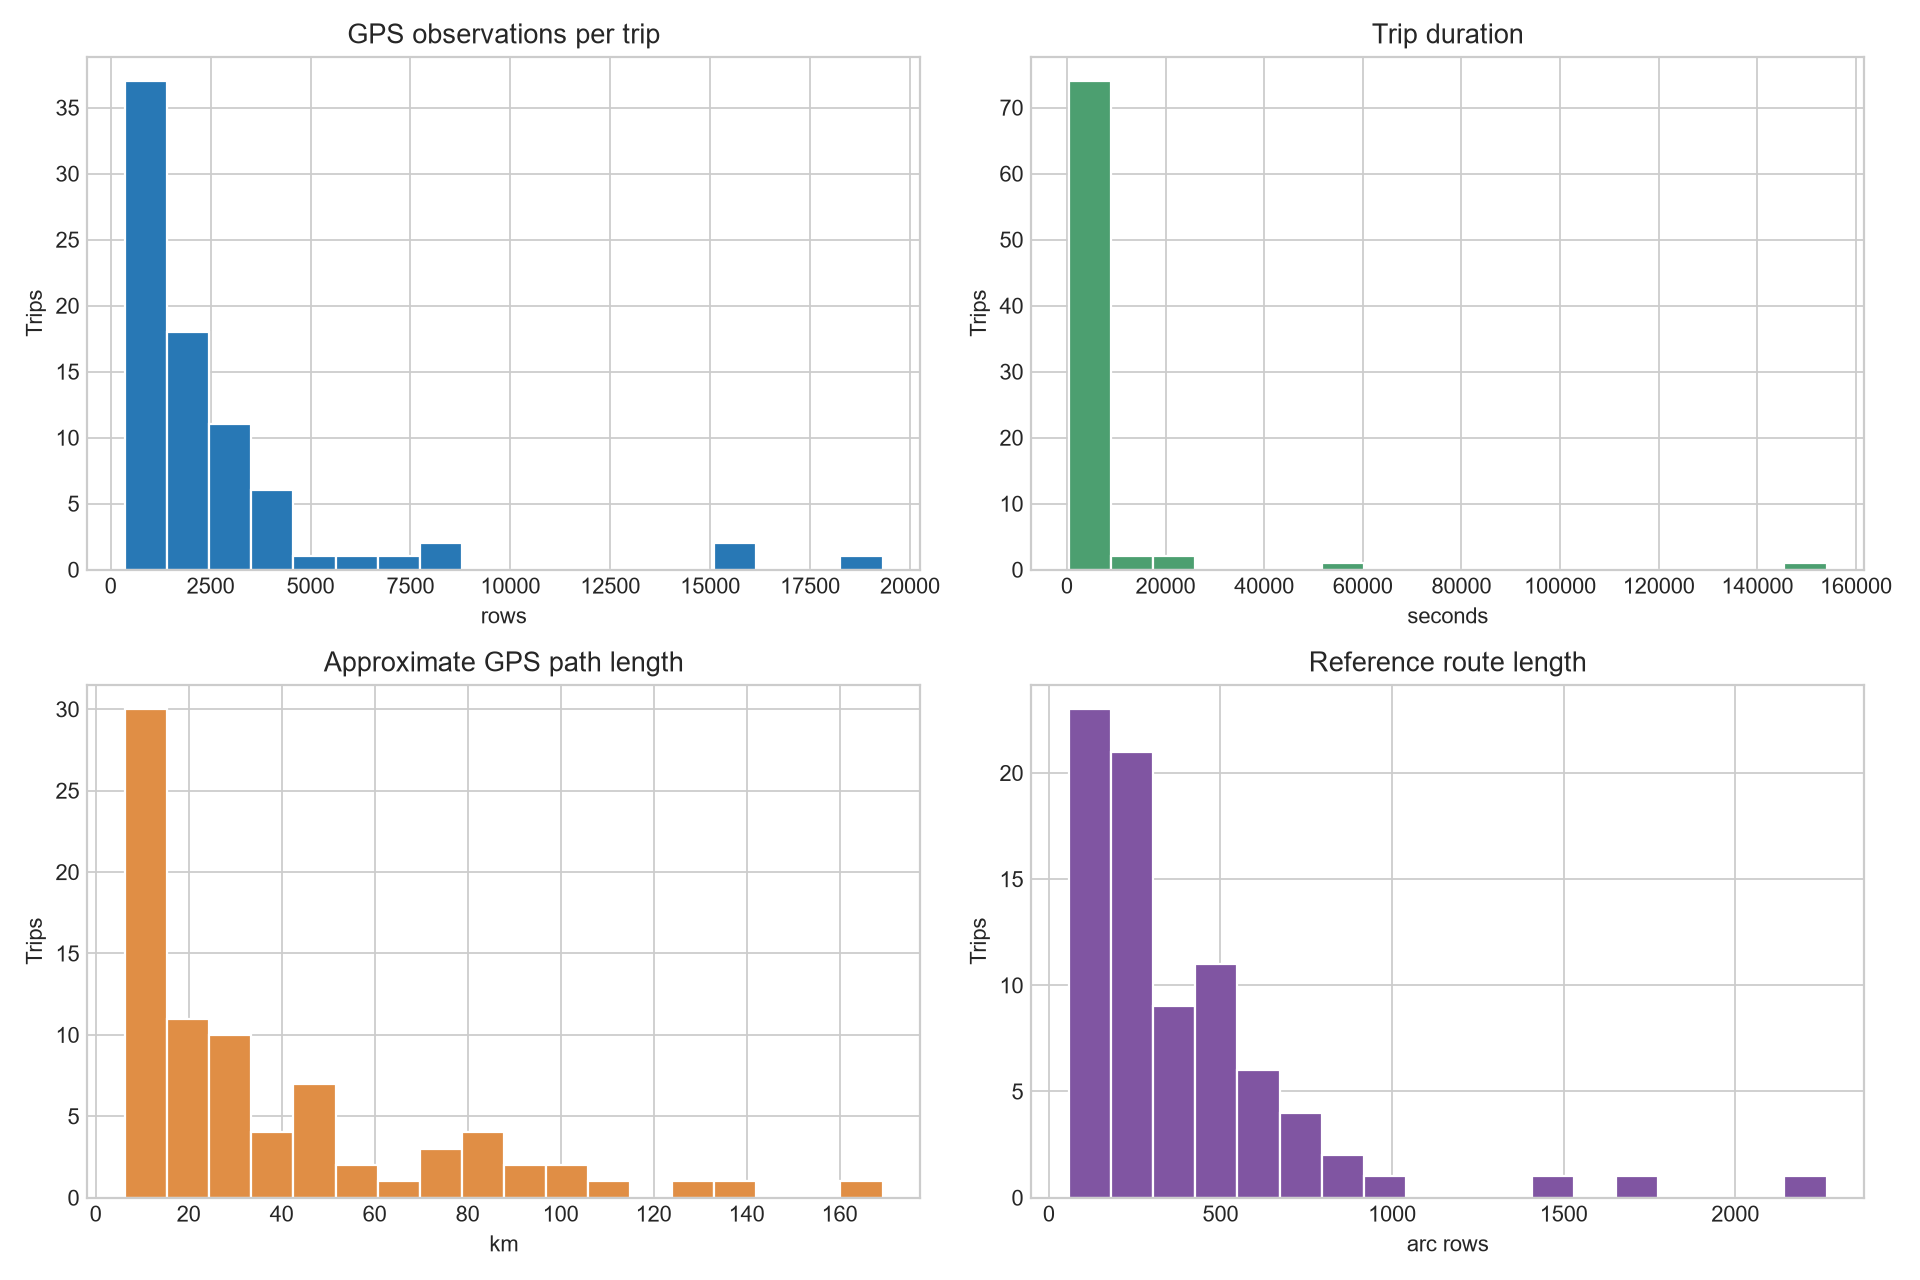

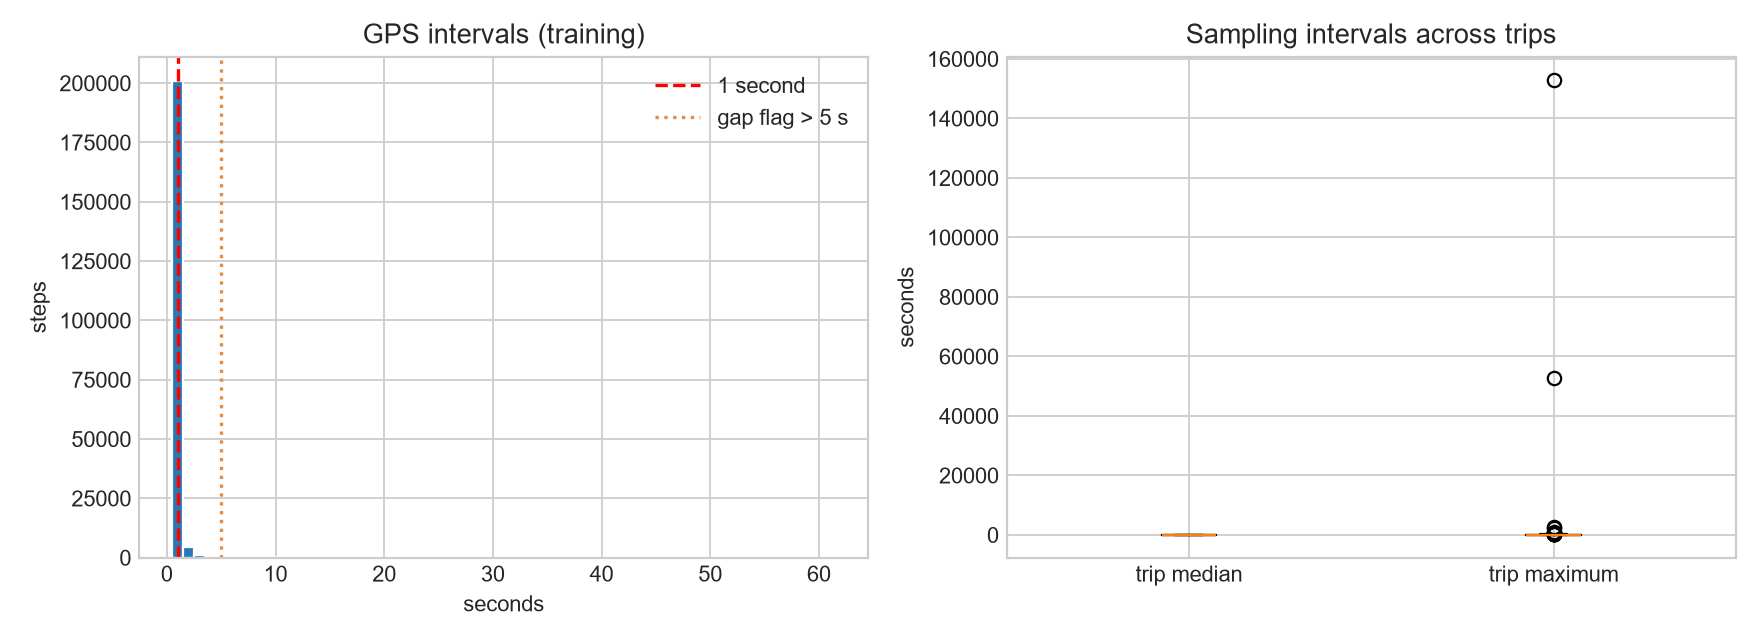

count    208337.000
mean          2.181
std         354.852
min           1.000
50%           1.000
90%           1.000
95%           1.000
99%           3.000
max      153064.000
dtype: float64

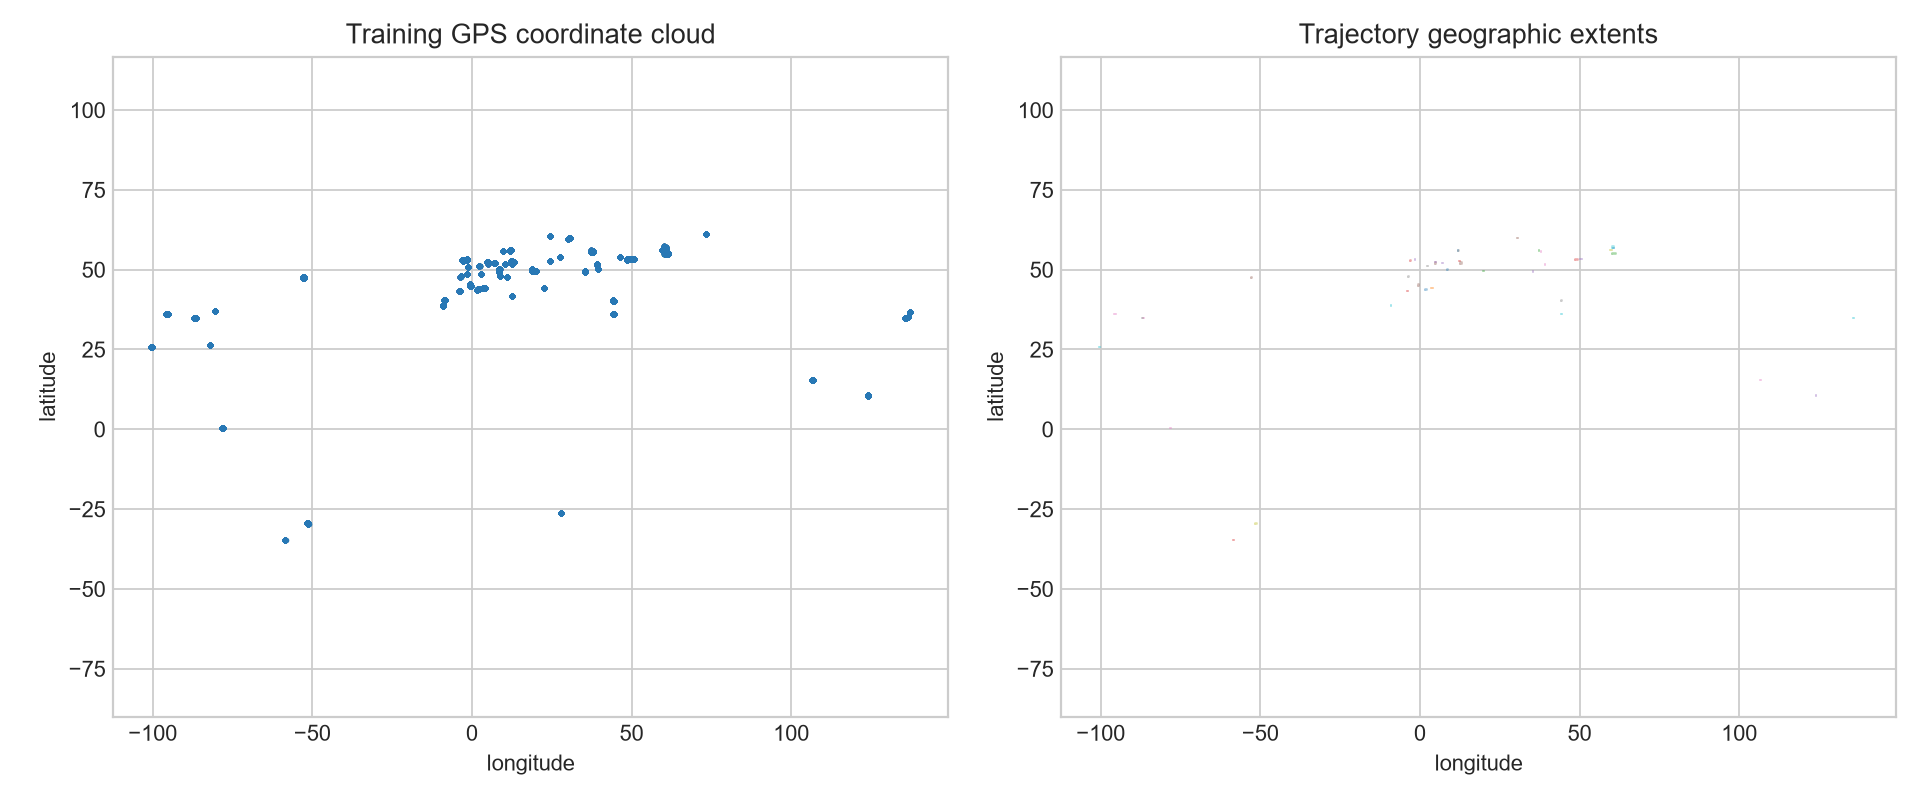

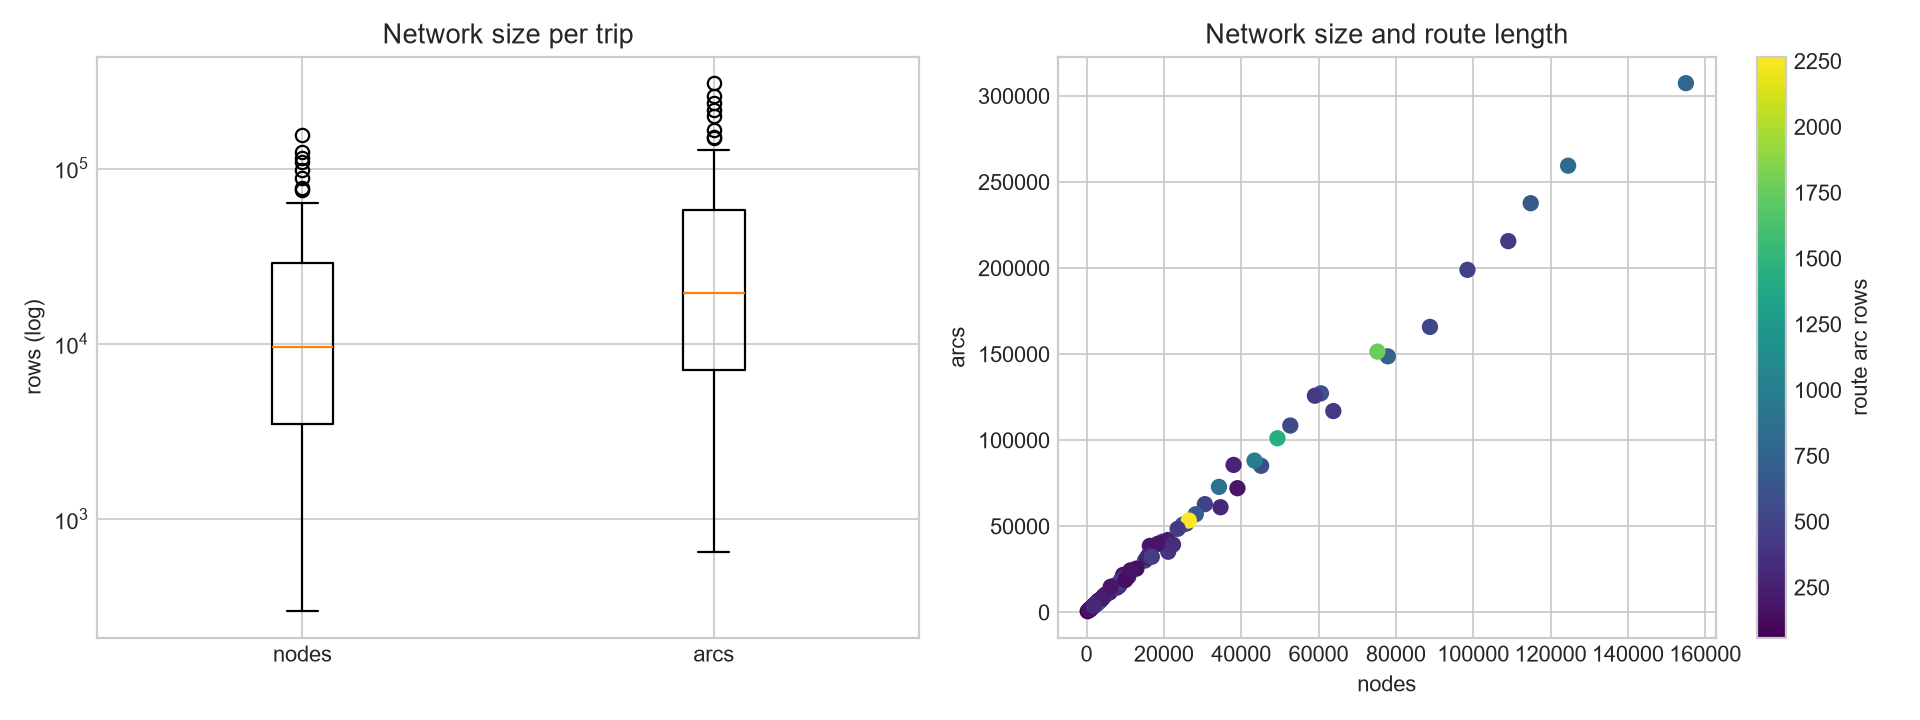

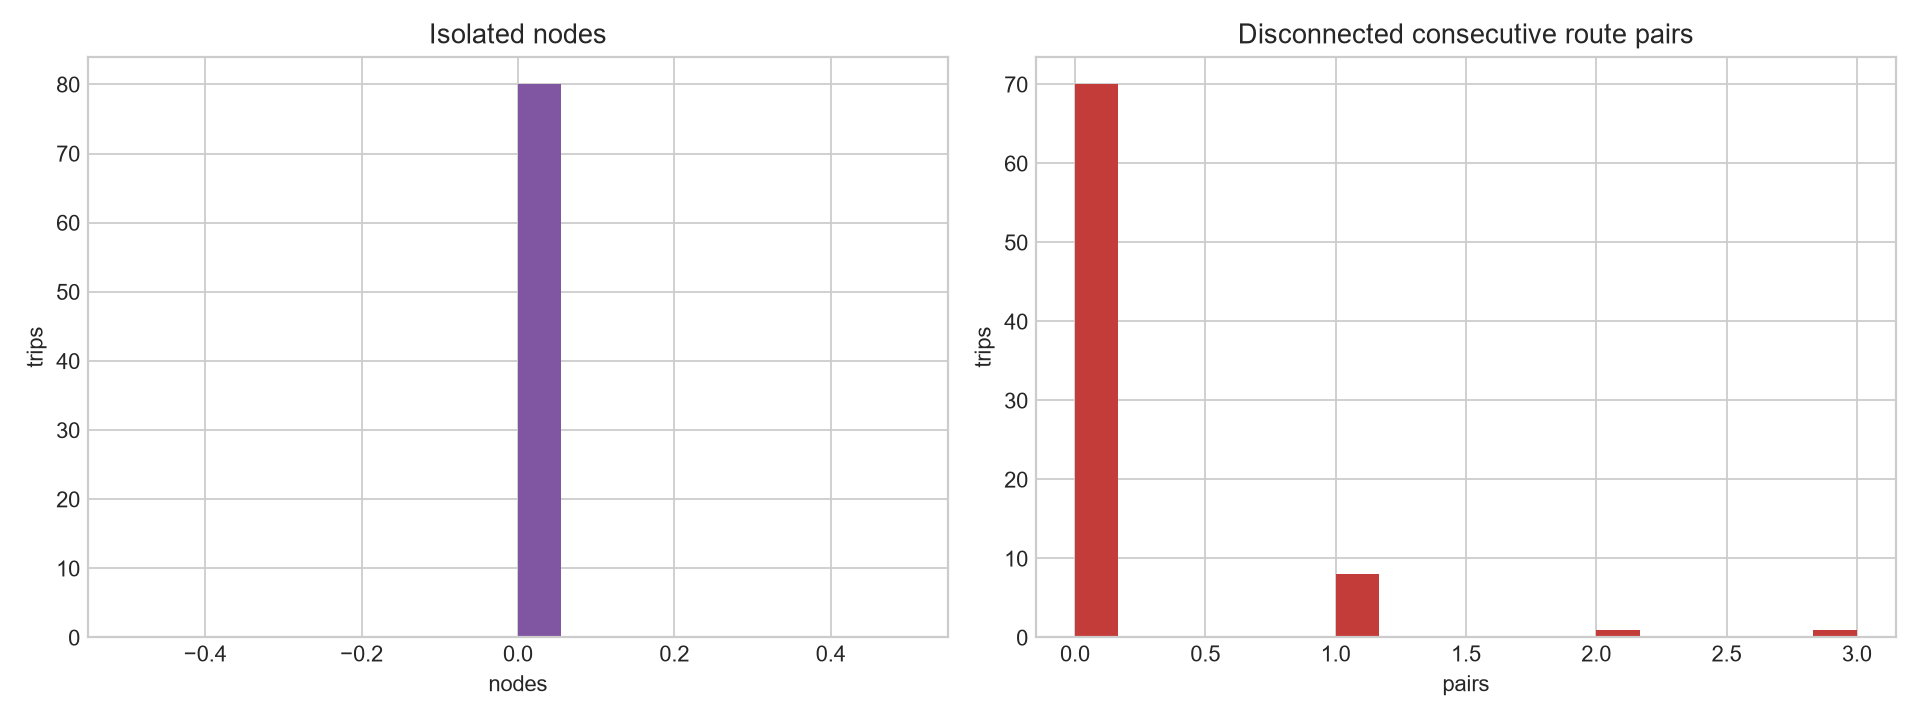

In [4]:
fig, ax = plt.subplots(2,2,figsize=(12,8))
for a, col, title, xlabel, color in [
    (ax[0,0],"gps_observations","GPS observations per trip","rows","#2878B5"),
    (ax[0,1],"duration_seconds","Trip duration","seconds","#4C9F70"),
    (ax[1,0],"gps_path_km","Approximate GPS path length","km","#E08E45"),
    (ax[1,1],"route_segments","Reference route length","arc rows","#8055A2")]:
    a.hist(summary[col].dropna(),bins=18,color=color,edgecolor="white")
    a.set(title=title,xlabel=xlabel,ylabel="Trips")
fig.tight_layout(); fig.savefig(GRAPH_DIR/"training_trip_distributions.png",dpi=160); display(Image(filename=str(GRAPH_DIR/"training_trip_distributions.png")))

all_dt=[]
for td in dirs("train"):
    tt=cache[("train",td.name)][".track"].timestamp_s.to_numpy(float)
    if len(tt)>1: all_dt.extend(np.diff(tt).tolist())
fig, ax=plt.subplots(1,2,figsize=(11,4))
pos=np.asarray(all_dt); pos=pos[pos>0]
ax[0].hist(pos,bins=np.arange(0.5,min(max(pos.max(initial=1),10),61)+1,1),color="#2878B5",edgecolor="white")
ax[0].axvline(1,color="red",ls="--",label="1 second"); ax[0].axvline(5,color="#E08E45",ls=":",label="gap flag > 5 s")
ax[0].set(title="GPS intervals (training)",xlabel="seconds",ylabel="steps"); ax[0].legend()
ax[1].boxplot([summary.interval_median_s.dropna(),summary.interval_max_s.dropna()],tick_labels=["trip median","trip maximum"])
ax[1].set(title="Sampling intervals across trips",ylabel="seconds")
fig.tight_layout(); fig.savefig(GRAPH_DIR/"training_sampling_intervals.png",dpi=160); display(Image(filename=str(GRAPH_DIR/"training_sampling_intervals.png")))
print("Interval quantiles in seconds"); display(pd.Series(all_dt).describe(percentiles=[.5,.9,.95,.99]).round(3))

fig,ax=plt.subplots(1,2,figsize=(12,5))
for td in dirs("train"):
    tr=cache[("train",td.name)][".track"]; ok=tr.longitude.between(-180,180)&tr.latitude.between(-90,90); tr=tr[ok]
    ax[0].scatter(tr.longitude,tr.latitude,s=2,alpha=.18,color="#2878B5")
    if len(tr):
        ax[1].plot([tr.longitude.min(),tr.longitude.max(),tr.longitude.max(),tr.longitude.min(),tr.longitude.min()],
                   [tr.latitude.min(),tr.latitude.min(),tr.latitude.max(),tr.latitude.max(),tr.latitude.min()],lw=.7,alpha=.4)
ax[0].set(title="Training GPS coordinate cloud",xlabel="longitude",ylabel="latitude")
ax[1].set(title="Trajectory geographic extents",xlabel="longitude",ylabel="latitude")
for a in ax:a.set_aspect("equal",adjustable="datalim")
fig.tight_layout();fig.savefig(GRAPH_DIR/"training_geographic_extent.png",dpi=160);display(Image(filename=str(GRAPH_DIR/"training_geographic_extent.png")))

fig,ax=plt.subplots(1,2,figsize=(12,4.5))
ax[0].boxplot([summary.node_rows,summary.arc_rows],tick_labels=["nodes","arcs"]);ax[0].set_yscale("log");ax[0].set(title="Network size per trip",ylabel="rows (log)")
sc=ax[1].scatter(summary.node_rows,summary.arc_rows,c=summary.route_segments,cmap="viridis",s=40)
ax[1].set(title="Network size and route length",xlabel="nodes",ylabel="arcs");fig.colorbar(sc,ax=ax[1],label="route arc rows")
fig.tight_layout();fig.savefig(GRAPH_DIR/"training_network_sizes.png",dpi=160);display(Image(filename=str(GRAPH_DIR/"training_network_sizes.png")))

fig,ax=plt.subplots(1,2,figsize=(12,4.5))
ax[0].hist(summary.isolated_nodes,bins=18,color="#8055A2");ax[0].set(title="Isolated nodes",xlabel="nodes",ylabel="trips")
ax[1].hist(summary.route_disconnected_pairs,bins=18,color="#C43C39");ax[1].set(title="Disconnected consecutive route pairs",xlabel="pairs",ylabel="trips")
fig.tight_layout();fig.savefig(GRAPH_DIR/"training_network_quality.png",dpi=160);display(Image(filename=str(GRAPH_DIR/"training_network_quality.png")))

## 5. Representative static road-network visualization

Arc rows are plotted as straight lines between endpoint coordinates because the raw files contain no curved road geometry.

Representative trip: 00000022


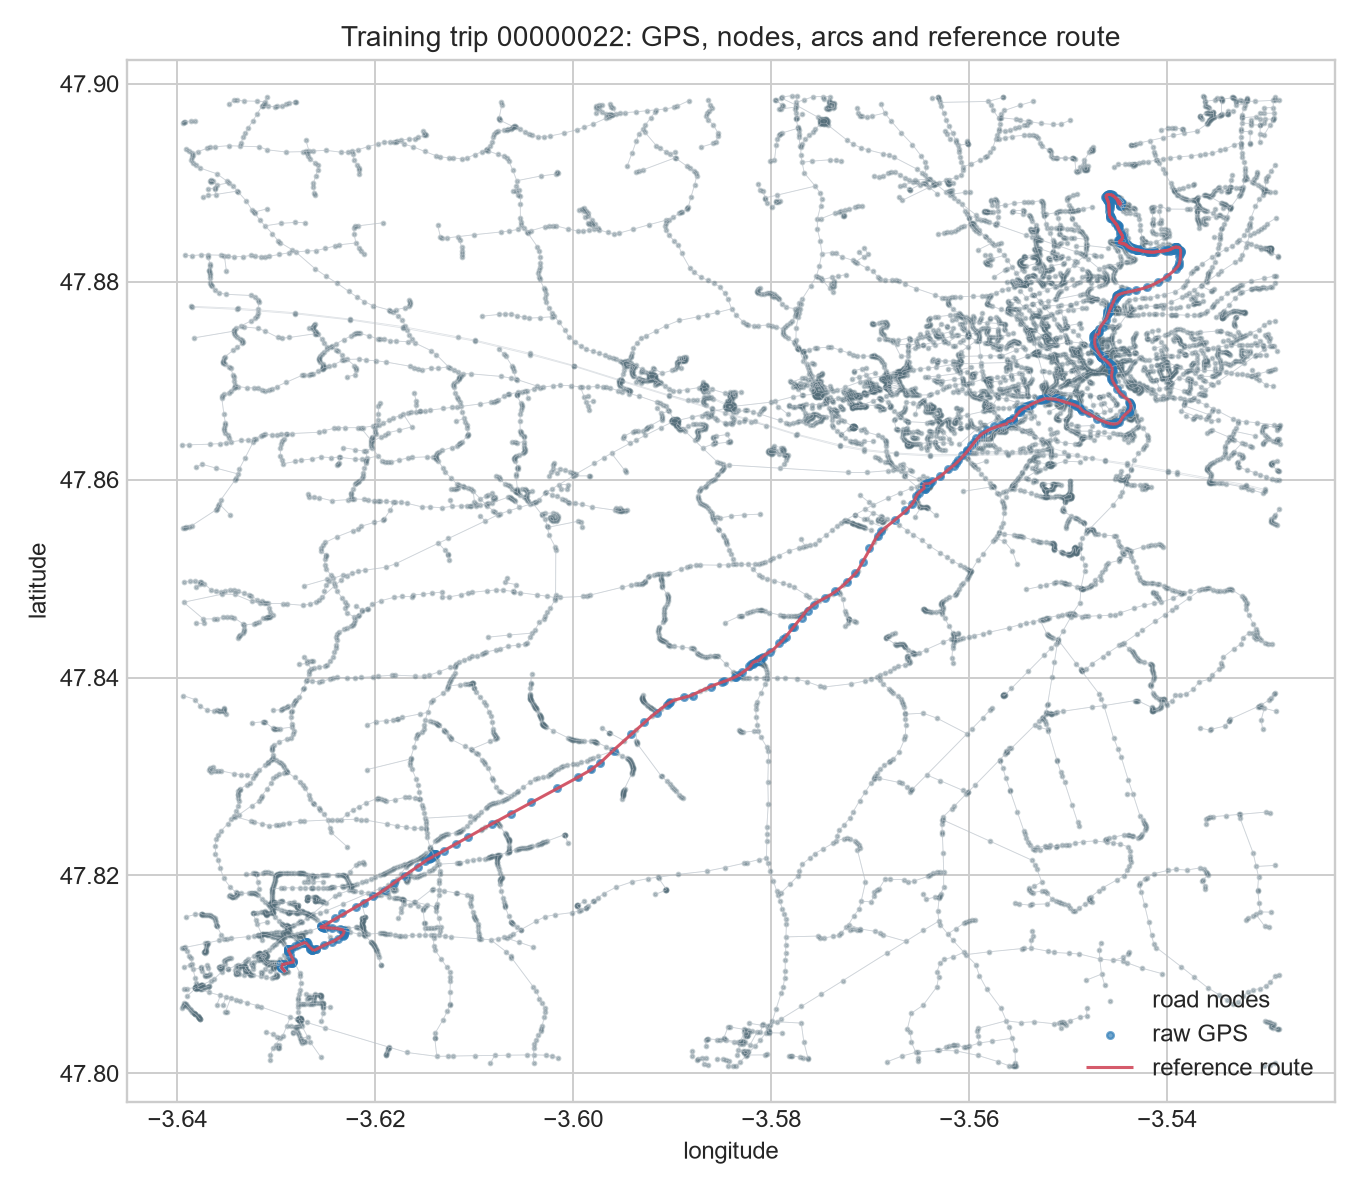

In [5]:
rep=str(summary.iloc[(summary.node_rows-summary.node_rows.median()).abs().argsort().iloc[0]].trip_id)
tr,nd,ar,rt=[cache[("train",rep)][s] for s in [".track",".nodes",".arcs",".route"]]
fig,ax=plt.subplots(figsize=(8,7))
valid=ar[ar.from_node_id.between(0,len(nd)-1)&ar.to_node_id.between(0,len(nd)-1)]
node_xy=nd[["longitude","latitude"]].to_numpy()
edge_ix=valid[["from_node_id","to_node_id"]].to_numpy(dtype=int)
ax.add_collection(LineCollection(node_xy[edge_ix],colors="#B8C0C8",linewidths=.35,alpha=.45))
ax.scatter(nd.longitude,nd.latitude,s=2,color="#546E7A",alpha=.35,label="road nodes")
ax.scatter(tr.longitude,tr.latitude,s=8,color="#2878B5",alpha=.65,label="raw GPS")
route_segments=[]
for i,x in enumerate(rt.arc_id):
    if 0<=x<len(ar):
        a,b=ar.iloc[x].tolist()
        if 0<=a<len(nd) and 0<=b<len(nd):
            route_segments.append(node_xy[[int(a),int(b)]])
if route_segments: ax.add_collection(LineCollection(route_segments,colors="#D1495B",linewidths=1.3,alpha=.9,label="reference route"))
ax.set(title=f"Training trip {rep}: GPS, nodes, arcs and reference route",xlabel="longitude",ylabel="latitude")
ax.set_aspect("equal",adjustable="datalim");ax.legend();fig.tight_layout()
fig.savefig(GRAPH_DIR/"representative_training_trip_network_route.png",dpi=170);display(Image(filename=str(GRAPH_DIR/"representative_training_trip_network_route.png")))
print("Representative trip:",rep)

## 6. Folium maps

Maps use selected training trips only. The grey background network is clipped to a small box around the GPS extent to keep HTML files practical; all route arcs are drawn. This is a map display choice, not source-data modification. Toggle the layers using the map control.

In [6]:
def make_map(trip):
    tr,nd,ar,rt=[cache[("train",trip)][s] for s in [".track",".nodes",".arcs",".route"]]
    ok=tr.longitude.between(-180,180)&tr.latitude.between(-90,90); tr=tr[ok]
    fmap=folium.Map([tr.latitude.mean(),tr.longitude.mean()],zoom_start=14,tiles="OpenStreetMap",control_scale=True)
    gps=folium.FeatureGroup(name="Raw GPS observations")
    pts=tr[["latitude","longitude"]].values.tolist()
    folium.PolyLine(pts,color="#2878B5",weight=3,opacity=.65,dash_array="5,5").add_to(gps)
    for i,row in tr.iterrows():
        folium.CircleMarker([row.latitude,row.longitude],radius=3,color="#2878B5",fill=True,fill_opacity=.8,
                            tooltip=f"GPS row {i}; t={row.timestamp_s:g}s").add_to(gps)
    gps.add_to(fmap)
    pad=.003; lon0,lon1=tr.longitude.min()-pad,tr.longitude.max()+pad; lat0,lat1=tr.latitude.min()-pad,tr.latitude.max()+pad
    near=set(nd.index[nd.longitude.between(lon0,lon1)&nd.latitude.between(lat0,lat1)])
    roads=folium.FeatureGroup(name="Road network (local crop)")
    selected=ar[ar.from_node_id.isin(near)&ar.to_node_id.isin(near)]
    for _,a,b in selected.itertuples(index=True,name=None):
        p,q=nd.iloc[int(a)],nd.iloc[int(b)]
        folium.PolyLine([[p.latitude,p.longitude],[q.latitude,q.longitude]],color="#8A949E",weight=1,opacity=.5).add_to(roads)
    for nid in near:
        p=nd.iloc[nid];folium.CircleMarker([p.latitude,p.longitude],radius=1.5,color="#546E7A",fill=True,fill_opacity=.5).add_to(roads)
    roads.add_to(fmap)
    ref=folium.FeatureGroup(name="Supplied reference route")
    for arc_id in rt.arc_id:
        if 0<=arc_id<len(ar):
            a,b=ar.iloc[arc_id].tolist()
            if 0<=a<len(nd) and 0<=b<len(nd):
                p,q=nd.iloc[a],nd.iloc[b]
                folium.PolyLine([[p.latitude,p.longitude],[q.latitude,q.longitude]],color="#D1495B",weight=4,opacity=.9,tooltip=f"Reference arc {arc_id}").add_to(ref)
    ref.add_to(fmap);folium.LayerControl(collapsed=False).add_to(fmap)
    legend="<div style='position:fixed;bottom:24px;left:24px;z-index:9999;background:white;padding:10px;border:1px solid #888'><b>Layers</b><br><span style='color:#2878B5'>●</span> GPS<br><span style='color:#8A949E'>━</span> road network<br><span style='color:#D1495B'>━</span> reference route</div>"
    fmap.get_root().html.add_child(folium.Element(legend))
    fmap.fit_bounds([[tr.latitude.min(),tr.longitude.min()],[tr.latitude.max(),tr.longitude.max()]])
    out=MAP_DIR/f"training_trip_{trip}_map.html";fmap.save(out);return out

median_trip=rep
gap_trip=str(summary.sort_values(["interval_max_s","gps_observations"],ascending=[False,True]).iloc[0].trip_id)
map_ids=list(dict.fromkeys([median_trip,gap_trip]))
for tid in map_ids: print("Saved map:",make_map(tid))
display(summary[summary.trip_id.isin(map_ids)][["trip_id","gps_observations","interval_max_s","node_rows","arc_rows","route_segments"]])

Saved map: C:\Users\danyl\Downloads\ML_hackathon\Part_2_EDA\outputs\maps\training_trip_00000022_map.html
Saved map: C:\Users\danyl\Downloads\ML_hackathon\Part_2_EDA\outputs\maps\training_trip_00000090_map.html


,trip_id,gps_observations,interval_max_s,node_rows,arc_rows,route_segments
17,00000022,474,22.0,9607,18982,376
72,00000090,536,153064.0,4010,7942,235


## 7. Quality overview and saved outputs

Reference routes are treated as supplied labels for exploration, not guaranteed independently verified ground truth. Connectivity uses an undirected projection to summarize components; route continuity uses directed end-to-start node matching.

In [7]:
overview=pd.DataFrame([
("Malformed records, all supplied partitions",int(inventory.malformed_rows.sum())),
("Missing files, all supplied partitions",int((~inventory.available).sum())),
("Missing parsed cells, all supplied partitions",int(inventory.missing_cells.sum())),
("Training invalid coordinate rows",int(summary.invalid_coordinates.sum())),
("Training duplicate complete GPS rows",int(summary.duplicate_gps_rows.sum())),
("Training duplicate node rows beyond first occurrence",int(summary.duplicate_node_rows.sum())),
("Training duplicate arc rows beyond first occurrence",int(summary.duplicate_arc_rows.sum())),
("Training one-second GPS intervals",int(summary.one_second_intervals.sum())),
("Training other GPS intervals",int(summary.other_intervals.sum())),
("Training repeated consecutive locations",int(summary.repeated_consecutive_locations.sum())),
("Training non-increasing timestamp steps",int(summary.non_increasing_steps.sum())),
("Training intervals > 5 seconds",int(summary.gaps_over_5s.sum())),
("Training invalid arc endpoints",int(summary.invalid_arc_endpoints.sum())),
("Training invalid route arc IDs",int(summary.invalid_route_arc_ids.sum())),
("Training disconnected consecutive route pairs",int(summary.route_disconnected_pairs.sum())),
],columns=["check","count"])
overview.to_csv(TABLE_DIR/"quality_overview.csv",index=False)
print("Partition inventory");display(partition_inventory)
print("Training trip medians");display(summary.select_dtypes("number").median().to_frame("median").round(3))
print("Quality overview");display(overview)
print("Overall one-second interval percentage:", round(100*summary.one_second_intervals.sum()/summary.intervals.sum(), 6))
print("Training trips with any route-disconnected arc pair:",int((summary.route_disconnected_pairs>0).sum()),"of",len(summary))
print("Graphs:",len(list(GRAPH_DIR.glob("*.png"))),"Tables:",len(list(TABLE_DIR.glob("*.csv"))),"Maps:",len(list(MAP_DIR.glob("*.html"))))

Partition inventory
Training trip medians
Quality overview
Overall one-second interval percentage: 96.503742
Training trips with any route-disconnected arc pair: 10 of 80
Graphs: 6 Tables: 9 Maps: 2


,partition,file_type,trips,files_present,parsed_rows,size_bytes,malformed_rows
0,student_test,.arcs,10,10,185041,1902157,0
1,student_test,.nodes,10,10,90689,1822179,0
2,student_test,.route,10,10,3477,18344,0
3,student_test,.track,10,10,19160,625911,0
4,train,.arcs,80,80,3876904,44267751,0
5,train,.nodes,80,80,1933485,38431647,0
6,train,.route,80,80,31336,165702,0
7,train,.track,80,80,208417,6872352,0


,median
gps_observations,1529.000
duration_seconds,1710.001
interval_median_s,1.000
interval_mean_s,1.059
interval_min_s,1.000
interval_max_s,11.000
one_second_intervals,1525.500
other_intervals,15.500
one_second_interval_percent,99.144
duplicate_node_rows,0.000


,check,count
0,"Malformed records, all supplied partitions",0
1,"Missing files, all supplied partitions",0
2,"Missing parsed cells, all supplied partitions",0
3,Training invalid coordinate rows,0
4,Training duplicate complete GPS rows,0
5,Training duplicate node rows beyond first occu...,89
6,Training duplicate arc rows beyond first occur...,1775
7,Training one-second GPS intervals,201053
8,Training other GPS intervals,7284
9,Training repeated consecutive locations,6
